<a href="https://colab.research.google.com/github/dianahshimwa/probability-and-gradient-descent/blob/main/part4_gradient_descent/part4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
from scipy.optimize import approx_fprime
import matplotlib.pyplot as plt

In [3]:
# 1. Initialize Matrices
X = np.array([[1.0, 3.0],
              [4.0, 10.0]])
y = np.array([5.0, 6.0])
m = np.array([-1.0, 2.0])
b = np.array([1.0, 1.0])
alpha = 0.01
iterations = 3

# Lists to store history for our Matplotlib graphs
m_hist = [m.copy()]
b_hist = [b.copy()]
error_hist = []

In [4]:
# 2. Mean Squared Error
# SciPy requires parameters to be in a single 1D array to calculate derivatives
def mse_cost(params):
    current_m = params[0:2]
    current_b = params[2:4]

    # Predict and calculate error
    y_hat = np.dot(X, current_m) + current_b
    error = y_hat - y

    # MSE Formula: (1/N) * sum((y_hat - y)^2)
    return (1.0 / len(y)) * np.sum(error**2)

# Calculate and store the initial error (Iteration 0)
initial_params = np.concatenate((m, b))
error_hist.append(mse_cost(initial_params))

In [5]:
# 3. Gradient Descent Loop
print("--- Starting Gradient Descent ---\n")
for i in range(1, iterations + 1):
    # Combine m and b for SciPy
    params = np.concatenate((m, b))

    # Using SciPy to compute the derivative of the MSE equation
    # approx_fprime requires the parameters, the function, and an epsilon step size
    epsilon = np.sqrt(np.finfo(float).eps)
    gradients = approx_fprime(params, mse_cost, epsilon)

    # Split gradients back into separate vectors for m and b
    grad_m = gradients[0:2]
    grad_b = gradients[2:4]

    # 4. Update Parameters (Explicit calculations, not abstracted)
    m = m - (alpha * grad_m)
    b = b - (alpha * grad_b)

    # Save the updated parameters and error for plotting
    m_hist.append(m.copy())
    b_hist.append(b.copy())
    current_mse = mse_cost(np.concatenate((m, b)))
    error_hist.append(current_mse)

    print(f"Iteration {i}:")
    print(f"  m = {m}")
    print(f"  b = {b}")
    print(f"  MSE = {current_mse:.4f}\n")

--- Starting Gradient Descent ---

Iteration 1:
  m = [-1.45        0.86999999]
  b = [0.99 0.89]
  MSE = 6.5033

Iteration 2:
  m = [-1.3331      1.17649999]
  b = [1.0185 0.9121]
  MSE = 2.4974

Iteration 3:
  m = [-1.369037    1.09558299]
  b = [1.036351 0.898653]
  MSE = 2.1645



In [6]:
# Compute final predictions
final_predictions = np.dot(X, m) + b
print(f"Final Predictions after {iterations} updates: {final_predictions}")
print(f"Actual Targets: {y}")

Final Predictions after 3 updates: [2.95406298 6.37833493]
Actual Targets: [5. 6.]


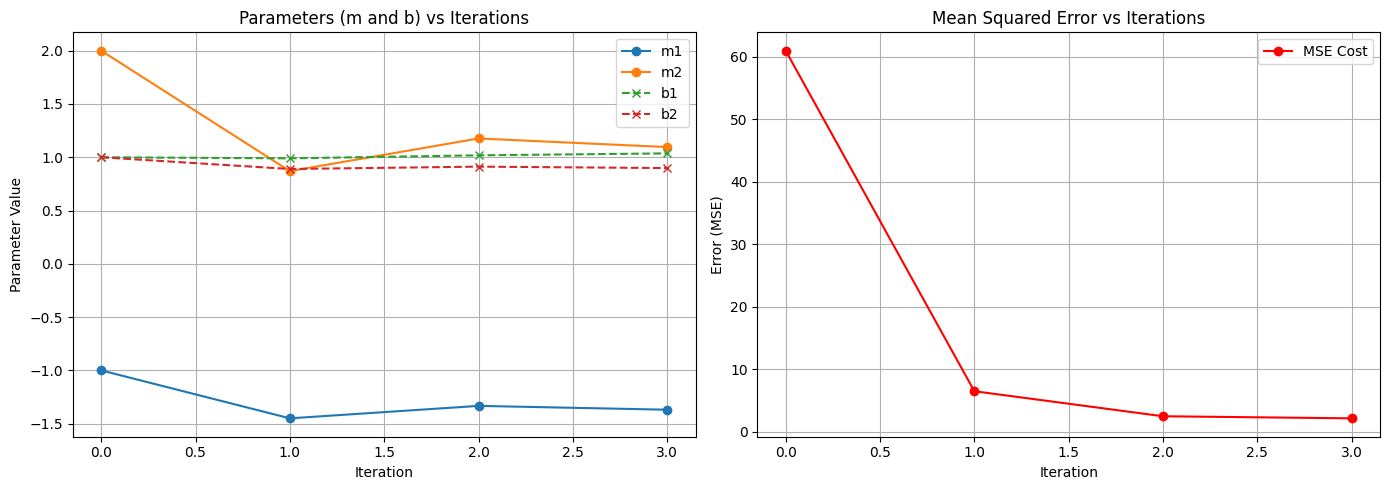

In [7]:
# 5. Generate Matplotlib Plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# How m and b change over iterations
ax1.plot(range(iterations + 1), [m[0] for m in m_hist], label='m1', marker='o')
ax1.plot(range(iterations + 1), [m[1] for m in m_hist], label='m2', marker='o')
ax1.plot(range(iterations + 1), [b[0] for b in b_hist], label='b1', linestyle='--', marker='x')
ax1.plot(range(iterations + 1), [b[1] for b in b_hist], label='b2', linestyle='--', marker='x')
ax1.set_title('Parameters (m and b) vs Iterations')
ax1.set_xlabel('Iteration')
ax1.set_ylabel('Parameter Value')
ax1.legend()
ax1.grid(True)

# How error changes over iterations
ax2.plot(range(iterations + 1), error_hist, label='MSE Cost', color='red', marker='o')
ax2.set_title('Mean Squared Error vs Iterations')
ax2.set_xlabel('Iteration')
ax2.set_ylabel('Error (MSE)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()